In [18]:
## Miniproject - Aircraft Detection

In [1]:
# Environement Preparation

import numpy as np
from scipy import ndimage
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt


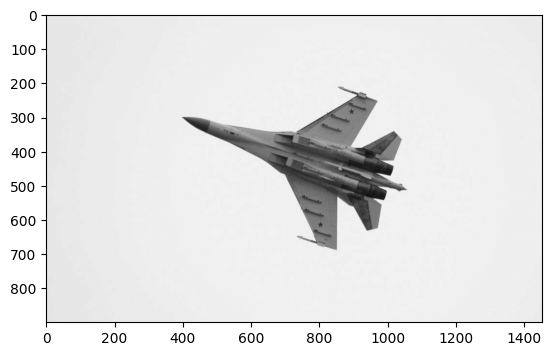

Dimensions de l'image :  (900, 1453)
Type de données :  uint8


In [2]:
# --- 1. Chargement de l'image et conversion en niveaux de gris ---

dossier_script = Path("Jupyter_WORKSPACE").parent
chemin_image = dossier_script / "Sukhoi35S_Picture_Base.png"
image_couleur = Image.open(chemin_image)
image_gris = np.array(image_couleur.convert("L"))
plt.imshow(image_gris, cmap='gray')
plt.show()

# Data checking

print("Dimensions de l'image : ", image_gris.shape)
print("Type de données : ", image_gris.dtype)

In [3]:
# --- 2. Réduction du bruit (flou léger) ---
image_lissee = ndimage.gaussian_filter(image_gris, sigma=2)


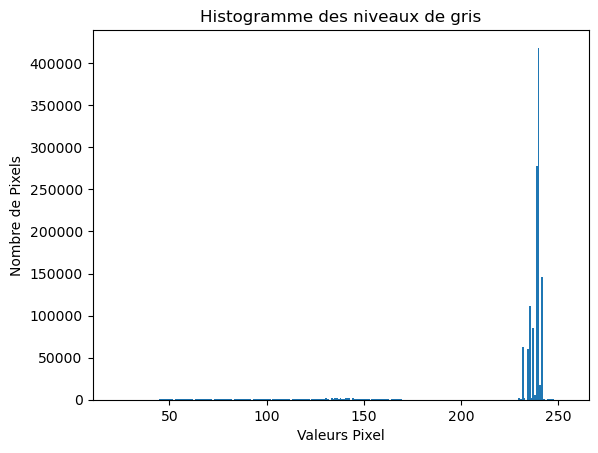

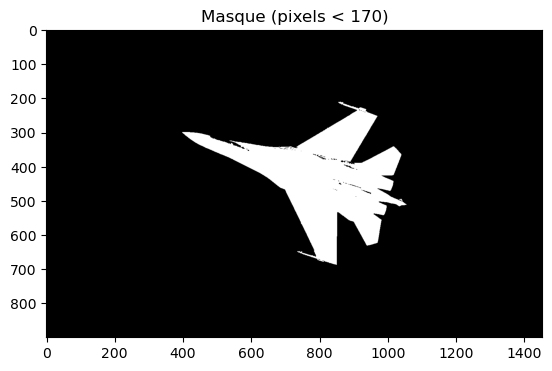

Nombre de pixels sélectionnés : 106439
Proportion de l'image : 0.08139405062323163


In [37]:
# --- 3. Seuillage par boolean indexing ---
# Détermination du seuil de détection sur l'image

# copy de l'image, puis création d'un histogramme
image_2 = np.copy(image_gris)
plt.hist(image_2.ravel(), bins=255)
plt.title("Histogramme des niveaux de gris")
plt.xlabel("Valeurs Pixel")
plt.ylabel("Nombre de Pixels")
plt.show()

# On suppose un avion plus sombre que le ciel : on choisit un seuil à ajuster selon l'image (à regarder sur l'histogramme, voir plus bas).

# Pré-traitement masque brut

seuil = 170
masque = image_gris < seuil

plt.imshow(masque, cmap='gray')
plt.title(f"Masque (pixels < {seuil})")
plt.show()

print("Nombre de pixels sélectionnés :", masque.sum())
print("Proportion de l'image :", masque.sum() / masque.size)

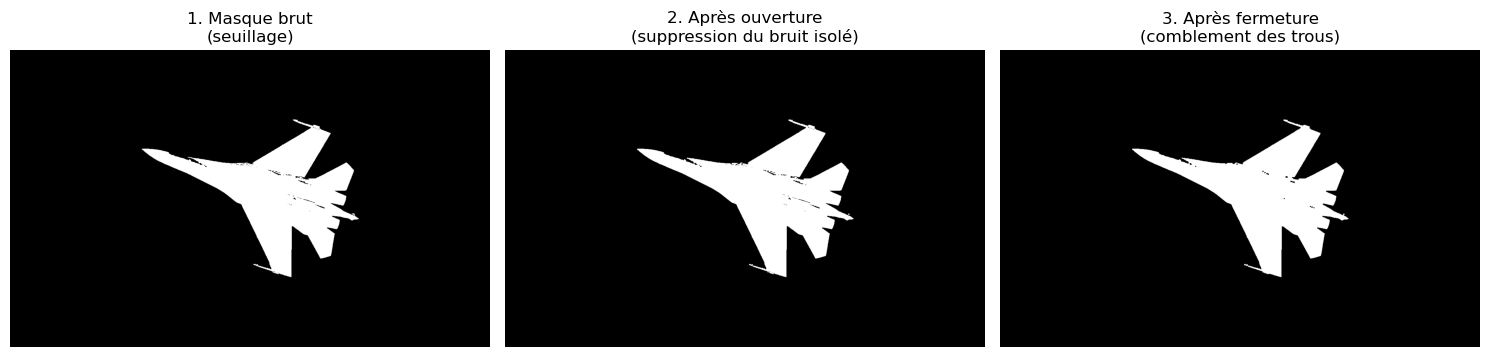

In [38]:
# --- 4. Nettoyage morphologique avec visualisation des 3 étapes ---
structure = np.ones((3, 3))

masque_ouvert = ndimage.binary_opening(masque, structure=structure)
masque_propre = ndimage.binary_closing(masque_ouvert, structure=structure)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(masque, cmap="gray")
axes[0].set_title("1. Masque brut\n(seuillage)")

axes[1].imshow(masque_ouvert, cmap="gray")
axes[1].set_title("2. Après ouverture\n(suppression du bruit isolé)")

axes[2].imshow(masque_propre, cmap="gray")
axes[2].set_title("3. Après fermeture\n(comblement des trous)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
# --- 5. Étiquetage des zones connectées ---
zones_etiquetees, nb_zones = ndimage.label(masque_propre)
print("Nombre de zones détectées (après filtrage) :", nb_zones)


Nombre de zones détectées (après filtrage) : 1


In [40]:
# --- 6. Taille de chaque zone, puis filtrage par boolean indexing ---
tailles = ndimage.sum(masque_propre, zones_etiquetees, range(1, nb_zones + 1))
print("Tailles des zones :", tailles)

taille_min_pixels = 500  # à ajuster selon la résolution de l'image
zones_trop_petites = tailles < taille_min_pixels

# On "efface" les petites zones : boolean indexing sur le tableau étiqueté
masque_a_effacer = np.isin(zones_etiquetees, np.where(zones_trop_petites)[0] + 1)
zones_etiquetees[masque_a_effacer] = 0


Tailles des zones : [106721.]


In [41]:
# --- 7. Décision de présence ---
zones_valides = np.unique(zones_etiquetees)
zones_valides = zones_valides[zones_valides != 0]  # on enlève le fond

presence_objet = len(zones_valides) > 0
print(f"Présence d'un objet détecté : {presence_objet}")
print(f"Nombre de zones candidates : {len(zones_valides)}")


Présence d'un objet détecté : True
Nombre de zones candidates : 1


In [42]:
# --- 8. Localisation de la plus grande zone détectée ---
if presence_objet:
    tailles_valides = ndimage.sum(
        masque_propre, zones_etiquetees, zones_valides
    )
    plus_grande_zone = zones_valides[np.argmax(tailles_valides)]
    boites = ndimage.find_objects(zones_etiquetees)
    boite_objet = boites[plus_grande_zone - 1]
    print(f"Boîte englobante (lignes, colonnes) : {boite_objet}")

    

Boîte englobante (lignes, colonnes) : (slice(213, 689, None), slice(400, 1055, None))


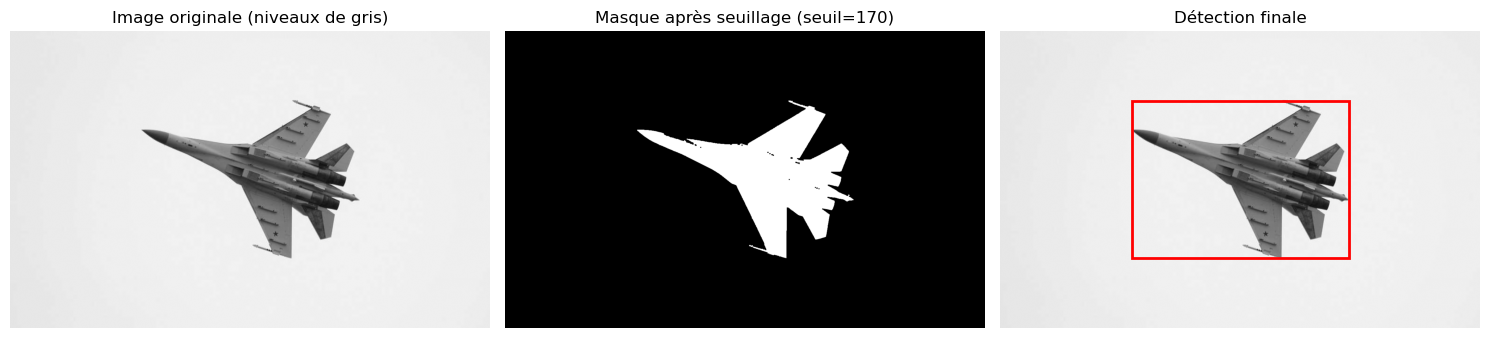

In [43]:
# --- 9. Visualisation ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_gris, cmap="gray")
axes[0].set_title("Image originale (niveaux de gris)")

axes[1].imshow(masque_propre, cmap="gray")
axes[1].set_title(f"Masque après seuillage (seuil={seuil})")

axes[2].imshow(image_gris, cmap="gray")

if presence_objet:
    y_slice, x_slice = boite_objet
    from matplotlib.patches import Rectangle
    rect = Rectangle(
        (x_slice.start, y_slice.start),
        x_slice.stop - x_slice.start,
        y_slice.stop - y_slice.start,
        edgecolor="red", facecolor="none", linewidth=2,
    )
    axes[2].add_patch(rect)
axes[2].set_title("Détection finale")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("resultat_detection.png", dpi=150)
plt.show()